# Assignment 3 — Does Quantization Make Code LLMs Brittle?

**NC State · CSC 591/791 · Trustworthy AI for Software Engineering · individual work**

Quantization papers report one headline number — usually pass@1 on clean, canonical
prompts — and call a 4-bit model "near-lossless" when that number barely moves. Real
prompts are not canonical: a function gets renamed, a docstring gets reworded, the
indentation changes. **When the clean score holds, does robustness hold too?**

In this assignment you will

1. **quantize** one code LLM yourself, four ways;
2. **evaluate** every version on the same robustness benchmarks, before and after quantization;
3. **analyse** whether quantization costs robustness that the clean score does not show.

There is **no answer key**. Nobody knows in advance whether 4-bit quantization hurts the
robustness of this model, so you are graded on whether your protocol is right, your
results are reproducible, and your claims match your evidence — not on reaching a
particular conclusion. A well-supported *"no significant change"* earns full credit.

### What is provided and what you write

The notebook provides the plumbing — data download, prompt construction, batched
generation with caching, sandboxed test execution, and the results/sample loggers. Cells
marked **`TODO`** are yours. Each TODO says what its function must return so that the
provided cells after it keep working.

| Part | What you do | Points |
|---|---|---|
| 1 | Load `fp16`, `int8`, `nf4`; run GPTQ yourself to produce `gptq4` | 20 |
| 2 | **E0** clean baseline, all four configurations | 10 |
| 3 | **E1** ReCode robustness, all four perturbation families | 25 |
| 4 | **E2** *or* **E3** (both → bonus) | 15 |
| 5 | Paired statistics and uncertainty | 10 |
| 6 | Report: the confound handled, flipped examples explained, claims matched to evidence | 15 |
| — | Submission: notebook with all outputs, run top to bottom; `README.md` explains your code | 5 |
| bonus | Both E2 and E3, or a fifth configuration (e.g. AWQ) | +5 |

### Rules

- Use a **GPU runtime**: *Runtime → Change runtime type → T4 GPU*.
- **Do not change** the model, the decoding settings, the prompt template (except inside E3),
  or the ReCode subset. They are fixed so that everyone's numbers are comparable.
- **Never use HumanEval or any ReCode file as GPTQ calibration data.** That leaks the test set
  into the quantized weights.
- AI assistance is allowed. Say in the report what you used it for; you remain responsible
  for every number.
- Submit two files to Gradescope: this notebook **with its outputs** (`.ipynb`) and a `README.md`
  explaining your code. Part 7 says what goes in each.

## Reading

| For | Paper |
|---|---|
| E1 | Wang et al., *ReCode: Robustness Evaluation of Code Generation Models*, ACL 2023 — [arXiv:2212.10264](https://arxiv.org/abs/2212.10264). Read §3 for the perturbation families and §4 for the metrics. |
| E1 (quantization) | Wei et al., *Greener yet Powerful: Taming Large Code Generation Models with Quantization* — [arXiv:2303.05378](https://arxiv.org/abs/2303.05378). They ran ReCode on quantized code models; compare your findings with theirs. |
| E2 | Fang et al., *EVALOOOP: A Self-Consistency-Centered Framework for Assessing Large Language Model Robustness in Programming* — [arXiv:2505.12185](https://arxiv.org/abs/2505.12185). |
| E3 | Sclar et al., *Quantifying Language Models' Sensitivity to Spurious Features in Prompt Design*, ICLR 2024 — [arXiv:2310.11324](https://arxiv.org/abs/2310.11324). |
| GPTQ | Frantar et al., *GPTQ*, ICLR 2023 — [arXiv:2210.17323](https://arxiv.org/abs/2210.17323). |
| int8 / NF4 | Dettmers et al., *LLM.int8()* — [arXiv:2208.07339](https://arxiv.org/abs/2208.07339); *QLoRA* (for NF4) — [arXiv:2305.14314](https://arxiv.org/abs/2305.14314). |

## 0. Setup

Run the install cell once. **If it changes the installed `torch`, restart the session
(*Runtime → Restart session*) and continue from the cell after it.** The next cell checks.

In [ ]:
!pip install -q "llmcompressor==0.14.0" "transformers==5.17.0" "bitsandbytes>=0.46" scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.9/394.9 kB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 147.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.2/240.2 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 53.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 5.6 MB/s eta 0:00:00


In [ ]:
import importlib.metadata as md
for pkg in ["torch", "transformers", "llmcompressor", "compressed-tensors", "bitsandbytes"]:
    print(f"{pkg:20s} {md.version(pkg)}")

import torch
assert torch.cuda.is_available(), "No GPU. Runtime -> Change runtime type -> T4 GPU."
print(torch.cuda.get_device_name(0))

torch                2.11.0+cu130
transformers         5.17.0
llmcompressor        0.14.0
compressed-tensors   0.19.0
bitsandbytes         0.50.2
NVIDIA L4


### Configuration

`QUICK = True` runs every evaluation on the first `N_QUICK` problems so you can debug the
whole notebook in minutes. **Set `QUICK = False` for the run you submit.**

Everything is written to the Colab VM's local disk (`/content/csc591-a3`). Generations are
cached there, so re-running a cell after an error resumes where it stopped. **The local disk
is wiped when the runtime is disconnected or deleted**, so keep the browser tab open during the
full run, and download the notebook as soon as it finishes.

In [ ]:
import os

MODEL_ID = "Qwen/Qwen2.5-Coder-1.5B-Instruct"   # fixed for the whole class
DEVICE = "cuda"
DTYPE = "float16"            # T4 has no fast bfloat16
QUICK = False                 # <- set to False for the graded run
N_QUICK = 20
MAX_NEW_TOKENS = 512
BATCH_SIZE = 16              # lower it if you run out of GPU memory
EXEC_TIMEOUT = 10            # seconds per test program

OUT_DIR = "/content/csc591-a3" if os.path.isdir("/content") else "./a3_out"

DATA_DIR = os.path.join(OUT_DIR, "data")
GEN_DIR = os.path.join(OUT_DIR, "generations")
FIG_DIR = os.path.join(OUT_DIR, "figures")
GPTQ_DIR = os.path.join(OUT_DIR, "gptq4-checkpoint")
for d in (DATA_DIR, GEN_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)
print("outputs ->", OUT_DIR)

outputs -> /content/csc591-a3


In [ ]:
import gc, json, sys, time, ast, re, random, hashlib, shutil, subprocess, tempfile, urllib.request
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, GenerationConfig

TORCH_DTYPE = getattr(torch, DTYPE)
random.seed(0); np.random.seed(0); torch.manual_seed(0)

## 1. Data: HumanEval and the ReCode perturbations

ReCode publishes its perturbed HumanEval files, so we download them rather than
regenerate them — everyone scores exactly the same prompts.

Two things about these files matter for your analysis:

- The **docstring** and **function-name** families perturb the ordinary HumanEval prompt.
  Their nominal (unperturbed) reference is `HumanEval.jsonl`.
- The **syntax** and **format** families perturb *partial code*: the prompt already
  contains the first half of the reference solution, and the model completes the rest.
  Their nominal reference is `humaneval_partial.jsonl`, **not** the ordinary prompt. Compare
  each perturbation with its own nominal set.

ReCode ships many transformations, several with up to 10 random seeds. To keep the compute
within a free T4, the class uses the fixed subset below: two transformations per family, seed 0.

In [ ]:
RECODE_BASE = "https://raw.githubusercontent.com/amazon-science/recode/main/dataset-release"

NOMINAL_FILES = {
    "nominal":         "nominal/HumanEval.jsonl",
    "nominal_partial": "nominal/humaneval_partial.jsonl",
}

# family -> {variant name: file}. Fixed for the whole class; do not change.
RECODE_SUBSET = {
    "docstring": {
        "BackTranslation":     "nlaugmenter/humaneval_BackTranslation_s0.jsonl",
        "ButterFingers":       "nlaugmenter/humaneval_ButterFingersPerturbation_s0.jsonl",
    },
    "func_name": {
        "CamelCase":           "func_name/humaneval_FuncRenameCamelCase_s0.jsonl",
        "ButterFinger":        "func_name/humaneval_FuncRenameButterFinger_s0.jsonl",
    },
    "syntax": {
        "VarRenamerCB":        "natgen/humaneval_VarRenamerCB_s0.jsonl",
        "DeadCodeInserter":    "natgen/humaneval_DeadCodeInserter_s0.jsonl",
    },
    "format": {
        "TabIndent":           "format/humaneval_tab_indent_s0.jsonl",
        "Doc2Comments":        "format/humaneval_doc2comments_s0.jsonl",
    },
}
# which nominal set each family is compared against
FAMILY_NOMINAL = {"docstring": "nominal", "func_name": "nominal",
                  "syntax": "nominal_partial", "format": "nominal_partial"}


def fetch(rel_path):
    local = os.path.join(DATA_DIR, rel_path.replace("/", "__"))
    if not os.path.exists(local):
        if rel_path.startswith("nominal/"):
            url = f"{RECODE_BASE}/{rel_path}"
        else:
            url = f"{RECODE_BASE}/perturbed_finalized/humaneval/full/{rel_path}"
        urllib.request.urlretrieve(url, local)
    with open(local) as f:
        rows = [json.loads(line) for line in f]
    assert len(rows) == 164, (rel_path, len(rows))
    return rows


DATASETS = {name: fetch(path) for name, path in NOMINAL_FILES.items()}
for family, variants in RECODE_SUBSET.items():
    for variant, path in variants.items():
        DATASETS[f"{family}/{variant}"] = fetch(path)

TASK_IDS = [r["task_id"] for r in DATASETS["nominal"]]
if QUICK:
    TASK_IDS = TASK_IDS[:N_QUICK]
print(len(DATASETS), "datasets,", len(TASK_IDS), "problems per dataset")

10 datasets, 164 problems per dataset


Look at one perturbed problem next to its nominal version before you go on. Pick a few
`task_id`s and families and read the prompts. You will need this to explain flipped examples
in your report.

In [ ]:
def show(dataset, task_id="HumanEval/0"):
    row = next(r for r in DATASETS[dataset] if r["task_id"] == task_id)
    print(f"--- {dataset}  entry_point={row['entry_point']}")
    print(row["prompt"])

show("nominal_partial")
show("syntax/VarRenamerCB")

--- nominal_partial  entry_point=has_close_elements
from typing import List


def has_close_elements(numbers: List[float], threshold: float) -> bool:
    """ Check if in given list of numbers, are any two numbers closer to each other than
    given threshold.
    >>> has_close_elements([1.0, 2.0, 3.0], 0.5)
    False
    >>> has_close_elements([1.0, 2.8, 3.0, 4.0, 5.0, 2.0], 0.3)
    True
    """
    for idx, elem in enumerate(numbers):
        for idx2, elem2 in enumerate(numbers):
            if idx != idx2:
                distance = abs(elem - elem2)

--- syntax/VarRenamerCB  entry_point=has_close_elements
from typing import List


def has_close_elements(e: List[float], threshold: float) -> bool:
    """Check if in given list of numbers, are any two numbers closer to each other than
    given threshold.
    >>> has_close_elements([1.0, 2.0, 3.0], 0.5)
    False
    >>> has_close_elements([1.0, 2.8, 3.0, 4.0, 5.0, 2.0], 0.3)
    True
    """
    for idx, elem in enumerate(e):
      

## 2. Prompting, generation, and test execution (provided)

**Prompt template (fixed).** The model sees the code in a user message, and its answer is
*prefilled* with that same code, so it continues the function exactly where the prompt
stops. This makes the instruct model behave like a completion model, which is what ReCode's
partial-code perturbations assume. Generation stops at the closing code fence.

**Decoding (fixed).** Greedy, `max_new_tokens=512`, no repetition penalty. `generate()`
fills any setting we leave unset from the model's own `generation_config`, which for Qwen
includes sampling settings and `repetition_penalty=1.1`, so every one of them is set
explicitly. The only thing that differs between your runs is the weights.

**Execution.** `prompt + completion` is first *sanitized*: only imports, function and class
definitions, and plain assignments are kept, so a self-test the model appended (often with
wrong expected values) cannot fail the program before the real tests run. The HumanEval tests
and `check(entry_point)` are then appended, and the program runs in a separate Python process
with a timeout. `SAMPLES` keeps the raw completion. Generated code is untrusted; it runs inside your
Colab VM, which is disposable.

In [ ]:
INSTRUCTION = "Complete the following Python function. Keep the function name and signature unchanged."
FENCE = "`" * 3
CHAT_STOP = [FENCE]


def chat_input(tok, prompt, instruction=INSTRUCTION):
    """Chat-formatted input whose assistant turn is prefilled with the code prompt."""
    body = prompt if prompt.endswith("\n") else prompt + "\n"
    user = f"{instruction}\n\n{FENCE}python\n{body}{FENCE}"
    text = tok.apply_chat_template([{"role": "user", "content": user}],
                                   tokenize=False, add_generation_prompt=True)
    return text + f"{FENCE}python\n" + prompt


def truncate_at_stop(text, stop):
    cut = min([i for s in stop for i in [text.find(s)] if i >= 0], default=len(text))
    return text[:cut]


GEN_STATS = defaultdict(lambda: {"tokens": 0, "seconds": 0.0})


@torch.inference_mode()
def generate(model, tok, inputs, stop, max_new_tokens=MAX_NEW_TOKENS, batch_size=BATCH_SIZE, stats_key=None):
    """Greedy batched generation. Returns one completion string per input, cut at the first stop string."""
    # generate() fills every field left unset here from the model's own generation_config, which
    # for Qwen includes repetition_penalty=1.1 and sampling settings. Set them all explicitly.
    gen_config = GenerationConfig(
        max_new_tokens=max_new_tokens, do_sample=False, stop_strings=stop or None,
        repetition_penalty=1.0, temperature=1.0, top_p=1.0, top_k=50,
        pad_token_id=tok.pad_token_id, eos_token_id=model.generation_config.eos_token_id)
    order = sorted(range(len(inputs)), key=lambda i: len(inputs[i]), reverse=True)
    outputs = [None] * len(inputs)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        enc = tok([inputs[i] for i in idx], return_tensors="pt", padding=True,
                  add_special_tokens=False).to(model.device)
        t0 = time.time()
        out = model.generate(**enc, generation_config=gen_config, tokenizer=tok)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        new = out[:, enc["input_ids"].shape[1]:]
        if stats_key:
            GEN_STATS[stats_key]["seconds"] += time.time() - t0
            GEN_STATS[stats_key]["tokens"] += int((new != tok.pad_token_id).sum())
        for i, text in zip(idx, tok.batch_decode(new, skip_special_tokens=True)):
            outputs[i] = truncate_at_stop(text, stop) if stop else text
    return outputs

In [ ]:
class GenCache:
    """Append-only cache of generations, one JSONL file per configuration.

    Entries are keyed by a hash of the exact model input and generation settings, so a changed
    prompt is regenerated and an identical one (e.g. E0 and E2 loop 1) is generated only once.
    """

    def __init__(self, config_id):
        self.path = os.path.join(GEN_DIR, f"{config_id}.jsonl")
        self.data = {}
        if os.path.exists(self.path):
            with open(self.path) as f:
                for line in f:
                    rec = json.loads(line)
                    self.data[rec["key"]] = rec["output"]

    DECODING = "greedy-rp1.0"   # part of the key: change it if you change the decoding settings

    @classmethod
    def key(cls, text, stop, max_new_tokens):
        return hashlib.sha1(json.dumps([text, stop, max_new_tokens, cls.DECODING]).encode()).hexdigest()

    def run(self, model, tok, inputs, stop, stats_key=None, chunk=64, max_new_tokens=MAX_NEW_TOKENS):
        keys = [self.key(x, stop, max_new_tokens) for x in inputs]
        todo = [(k, x) for k, x in dict(zip(keys, inputs)).items() if k not in self.data]
        for start in range(0, len(todo), chunk):
            part = todo[start:start + chunk]
            outs = generate(model, tok, [x for _, x in part], stop, stats_key=stats_key,
                            max_new_tokens=max_new_tokens)
            with open(self.path, "a") as f:
                for (k, _), o in zip(part, outs):
                    self.data[k] = o
                    f.write(json.dumps({"key": k, "output": o}) + "\n")
            print(f"  generated {min(start + chunk, len(todo))}/{len(todo)}", end="\r")
        return [self.data[k] for k in keys]

In [ ]:
def sanitize(code):
    """Keep imports, definitions and call-free assignments; drop top-level code the model added
    (its own asserts, prints, `if __name__ == "__main__":` blocks). Unparsable code is returned
    unchanged and fails at execution."""
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return code
    defs = (ast.Import, ast.ImportFrom, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)
    tree.body = [n for n in tree.body if isinstance(n, defs) or
                 (isinstance(n, (ast.Assign, ast.AnnAssign))
                  and not any(isinstance(c, ast.Call) for c in ast.walk(n)))]
    return ast.unparse(tree)


def build_program(prompt, completion, row):
    return f"{sanitize(prompt + completion)}\n\n{row['test']}\n\ncheck({row['entry_point']})\n"


def run_program(program, timeout=EXEC_TIMEOUT):
    """Run a program in a fresh interpreter. Returns (passed, status)."""
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "prog.py")
        with open(path, "w") as f:
            f.write(program)
        try:
            r = subprocess.run([sys.executable, path], cwd=tmp, capture_output=True,
                               text=True, timeout=timeout)
        except subprocess.TimeoutExpired:
            return False, "timeout"
    if r.returncode == 0:
        return True, "passed"
    err = r.stderr.strip().splitlines()
    return False, (err[-1][:200] if err else f"exit {r.returncode}")


def run_programs(programs, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(run_program, programs))


# sanity check: the reference solutions must pass
_rows = [r for r in DATASETS["nominal"] if r["task_id"] in TASK_IDS]
_res = run_programs([build_program(r["prompt"], r["canonical_solution"], r) for r in _rows])
print("reference solutions passing:", sum(p for p, _ in _res), "/", len(_rows))

reference solutions passing: 164 / 164


In [ ]:
SAMPLES = []      # one dict per generation (prompt, raw output, verdict)
RESULTS = []      # one dict per metric
CONFIG_META = {
    "fp16":  {"method": "none",               "bits": 16},
    "int8":  {"method": "bnb-llm.int8",       "bits": 8},
    "nf4":   {"method": "bnb-nf4",            "bits": 4},
    "gptq4": {"method": "gptq-w4a16-g128",    "bits": 4},
}


def record_result(config, eval_id, variant, metric, n, value, ci_low=None, ci_high=None):
    meta = CONFIG_META[config]
    RESULTS.append({"config": config, "method": meta["method"], "bits": meta["bits"],
                    "eval": eval_id, "variant": variant, "metric": metric, "n": n,
                    "value": value, "ci_low": ci_low, "ci_high": ci_high})


def evaluate_dataset(config, model, tok, cache, dataset, eval_id, instruction=INSTRUCTION, variant=None):
    """Generate and test every problem of one dataset. Returns {task_id: passed}."""
    rows = [r for r in DATASETS[dataset] if r["task_id"] in TASK_IDS]
    variant = variant or dataset
    inputs = [chat_input(tok, r["prompt"], instruction) for r in rows]
    outs = cache.run(model, tok, inputs, CHAT_STOP, stats_key=config)
    verdicts = run_programs([build_program(r["prompt"], o, r) for r, o in zip(rows, outs)])
    passed = {}
    for r, o, (ok, status) in zip(rows, outs, verdicts):
        passed[r["task_id"]] = ok
        SAMPLES.append({"config": config, "eval": eval_id, "variant": variant, "item_id": r["task_id"],
                        "prompt": r["prompt"], "output": o, "passed": ok, "status": status})
    return passed

## 3. Part 1 — Quantize the model (20 pts)

| ID | Precision | Method | Calibration data |
|---|---|---|---|
| `fp16` | 16-bit | none — the baseline | — |
| `int8` | 8-bit | LLM.int8() via `bitsandbytes` | none |
| `nf4` | 4-bit | NF4 via `bitsandbytes` | none |
| `gptq4` | 4-bit weights, 16-bit activations | GPTQ, group size 128, via `llmcompressor` | **you choose** |

`int8` and `nf4` quantize at load time. `gptq4` is the one where you actually run a
quantization algorithm: choose a calibration set, run GPTQ, save the checkpoint, and reload it.

### TODO 1a — `load_model`

In [ ]:
def load_tokenizer():
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    tok.padding_side = "left"          # required for batched generation with a decoder-only model
    return tok


def load_model(config):
    """Return the model for `config` in eval mode on the GPU.

    fp16  : the original weights in float16
    int8  : LLM.int8() through BitsAndBytesConfig
    nf4   : 4-bit NF4 through BitsAndBytesConfig, computing in float16
    gptq4 : the checkpoint you saved to GPTQ_DIR in TODO 1b
    """
    # TODO: implement the four cases. Hints: AutoModelForCausalLM.from_pretrained(...,
    # dtype=TORCH_DTYPE, device_map=DEVICE, quantization_config=...). Look up the
    # BitsAndBytesConfig fields for 8-bit and for 4-bit NF4.


    if config == "fp16":
        model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID, dtype=TORCH_DTYPE, device_map=DEVICE
        )

    elif config == "int8":
        quant_config = BitsAndBytesConfig(load_in_8bit=True)
        model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID, dtype=TORCH_DTYPE, device_map=DEVICE,
            quantization_config=quant_config
        )

    elif config == "nf4":
        quant_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=TORCH_DTYPE
        )
        model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID, dtype=TORCH_DTYPE, device_map=DEVICE,
            quantization_config=quant_config
        )

    elif config == "gptq4":
        model = AutoModelForCausalLM.from_pretrained(
            GPTQ_DIR, dtype=TORCH_DTYPE, device_map=DEVICE
        )

    else:
        raise ValueError(f"Unknown config: {config}")

    return model.eval()


### TODO 1b — run GPTQ

Use `llmcompressor`'s `oneshot` with a `GPTQModifier` whose scheme is `"W4A16"` (4-bit
symmetric integer weights, group size 128, 16-bit activations). Leave `lm_head` unquantized.
Save with `save_compressed=True`, and save the tokenizer next to it.

**Calibration data is your design decision; justify it in the report.** GPTQ chooses each
layer's rounding to minimise the error on the calibration activations, so what you
calibrate on may matter. Some options: code instructions (e.g.
`theblackcat102/evol-codealpaca-v1`), general text (e.g. `wikitext`), or chat data. Record
the dataset, number of samples and sequence length. **HumanEval and ReCode are forbidden.**

**Load the model in float32 for calibration**, not float16. In float16 the T4 run overflows
inside the network, the Hessians become invalid, and llmcompressor quietly quantizes almost
every layer with plain round-to-nearest instead of GPTQ — you would be comparing NF4 against
RTN without knowing it. The cell below checks for this and refuses to keep such a checkpoint.
(Evaluation still loads the saved checkpoint in float16.)

On a T4, 256 samples of 512 tokens takes a few minutes. The cell skips itself if a
checkpoint already exists.

In [ ]:
from llmcompressor import oneshot
from llmcompressor.modifiers.quantization import GPTQModifier
from datasets import load_dataset

CALIB_DATASET = "theblackcat102/evol-codealpaca-v1"        # TODO: name of the calibration dataset you chose
NUM_CALIB_SAMPLES = 256
CALIB_SEQ_LEN = 512


def build_calibration_set(tok):
    """Return a datasets.Dataset with tokenized `input_ids` and `attention_mask` columns."""

    raw = load_dataset(
        CALIB_DATASET,
        split=f"train[:{NUM_CALIB_SAMPLES}]"
    )

    def tokenize_sample(example):
        messages = [
            {"role": "user", "content": example["instruction"]},
            {"role": "assistant", "content": example["output"]},
        ]
        text = tok.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=False,
        )
        return tok(
            text,
            truncation=True,
            max_length=CALIB_SEQ_LEN,
            padding=False,
            add_special_tokens=False,
        )

    return raw.map(
        tokenize_sample,
        remove_columns=raw.column_names,
    )



def run_gptq():

    tok = load_tokenizer()
    calib_dataset = build_calibration_set(tok)

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        dtype=torch.float32,
        device_map=DEVICE,
    )

    recipe = GPTQModifier(
        targets="Linear",
        scheme="W4A16",
        ignore=["lm_head"],
    )

    oneshot(
        model=model,
        dataset=calib_dataset,
        recipe=recipe,
        num_calibration_samples=NUM_CALIB_SAMPLES,
        max_seq_length=CALIB_SEQ_LEN,
    )

    model.save_pretrained(GPTQ_DIR, save_compressed=True)
    tok.save_pretrained(GPTQ_DIR)

    del model
    gc.collect()
    torch.cuda.empty_cache()



from loguru import logger as _llmc_logger


def run_gptq_checked(max_fallback=0.10):
    """Run GPTQ and fail if too many layers silently fell back to round-to-nearest."""
    warnings_seen = []
    sink = _llmc_logger.add(lambda m: warnings_seen.append(m.record["message"]), level="WARNING")
    try:
        run_gptq()
    finally:
        _llmc_logger.remove(sink)
    for msg in warnings_seen:
        m = re.search(r"Hessian inversion failed for (\d+)/(\d+) modules", msg)
        if m and int(m.group(1)) / int(m.group(2)) > max_fallback:
            shutil.rmtree(GPTQ_DIR, ignore_errors=True)
            raise RuntimeError(
                f"GPTQ fell back to round-to-nearest for {m.group(1)}/{m.group(2)} layers, so this "
                "checkpoint is not a GPTQ model. It was deleted. Check the calibration dtype and data.")
    print("GPTQ fallback check passed")


if not os.path.exists(os.path.join(GPTQ_DIR, "config.json")):
    t0 = time.time()
    run_gptq_checked()
    print(f"GPTQ done in {time.time() - t0:.0f}s")
else:
    print("using existing checkpoint at", GPTQ_DIR)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3426: UserWarning: Attempting to save a model with offloaded modules. Ensure that unallocated cpu memory exceeds the `shard_size` (50GB default)
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2026-10-15T21:14:49.9803 | resave_config | INFO - Resaved original config with patched fields to /content/csc591-a3/gptq4-checkpoint/config.json


Dispatching model: 100%|██████████| 371/371 [00:00<00:00, 15782.61it/s]


GPTQ fallback check passed
GPTQ done in 242s


### Efficiency (provided)

Record what each configuration buys you. Note one subtlety for your report: `transformers`
stores the GPTQ checkpoint compressed on disk, but on a T4 it **decompresses the weights to
fp16 on the first forward pass**. Its numbers are the numbers of 4-bit weights, but its GPU
memory and speed are not what a dedicated int4 kernel (e.g. vLLM) would give.

In [ ]:
def dir_size_gb(path):
    return sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(path) for f in fs) / 1e9


def efficiency_row(config, model):
    row = {"config": config, "weights_in_memory_gb": model.get_memory_footprint() / 1e9}
    if config == "gptq4":
        row["checkpoint_on_disk_gb"] = dir_size_gb(GPTQ_DIR)
    if torch.cuda.is_available():
        row["peak_gpu_memory_gb"] = torch.cuda.max_memory_allocated() / 1e9
    s = GEN_STATS[config]
    row["tokens_per_second"] = s["tokens"] / s["seconds"] if s["seconds"] else None
    return row


EFFICIENCY = []

### Sanity check before the long runs

Load one configuration and look at its output on two problems. If the completion is empty
or garbled, fix that before you spend GPU time.

In [ ]:
tok = load_tokenizer()
_model = load_model("fp16")
_rows = [r for r in DATASETS["nominal"]][:2]
for r, o in zip(_rows, generate(_model, tok, [chat_input(tok, r["prompt"]) for r in _rows], CHAT_STOP)):
    print("=" * 60, r["task_id"]); print(r["prompt"] + o)
del _model; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

============================================================ HumanEval/0
from typing import List


def has_close_elements(numbers: List[float], threshold: float) -> bool:
    """ Check if in given list of numbers, are any two numbers closer to each other than
    given threshold.
    >>> has_close_elements([1.0, 2.0, 3.0], 0.5)
    False
    >>> has_close_elements([1.0, 2.8, 3.0, 4.0, 5.0, 2.0], 0.3)
    True
    """
    numbers.sort()  # Sort the list to make it easier to check for close elements
    for i in range(len(numbers) - 1):
        if abs(numbers[i] - numbers[i + 1]) < threshold:
            return True
    return False

============================================================ HumanEval/1
from typing import List


def separate_paren_groups(paren_string: str) -> List[str]:
    """ Input to this function is a string containing multiple groups of nested parentheses. Your goal is to
    separate those group into separate strings and return the list of those.
    Separate gro

## 4. Parts 2–4 — Run the evaluations

The loop below loads one configuration at a time, runs **E0** and **E1** on it, and runs
**E2** and/or **E3** if you set the flags. Everything is cached, so if the session dies,
re-run the setup cells and this cell; finished generations are not regenerated.

**Time budget (measured on a free Colab T4, `QUICK = False`):** the GPTQ step takes about
10 minutes, and E0 + E1 + E2 over all four configurations about **2.5 hours**. E3 adds
roughly another hour (estimate). `int8` (LLM.int8()) generates about 3× slower than the
others and dominates the total. Do the `QUICK` run first, then start the full run early —
on a free runtime that may mean a separate session.

The `TODO` functions this loop calls are defined in the cells after it — run those
cells first, then come back to this one. E0 and E1 need nothing from you to *run*; your
E1 work is the metric computation in Part 3.

In [ ]:
CONFIGS = ["fp16", "int8", "nf4", "gptq4"]
RUN_E2 = True     # EVALOOOP self-consistency loop  (do at least one of E2/E3)
RUN_E3 = False    # prompt-template sensitivity
E2_MAX_LOOPS = 3

PASS = defaultdict(dict)      # PASS[config][dataset or variant] = {task_id: passed}
E2_OUT = {}                   # E2_OUT[config] = output of run_evaloop

In [ ]:
def run_all():
    tok = load_tokenizer()
    for config in CONFIGS:
        print(f"===== {config}")
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        model = load_model(config)
        cache = GenCache(config)

        # E0: both nominal sets (the partial one is the reference for syntax/format)
        for ds in NOMINAL_FILES:
            PASS[config][ds] = evaluate_dataset(config, model, tok, cache, ds, "E0")
        # E1: ReCode subset
        for family, variants in RECODE_SUBSET.items():
            for variant in variants:
                name = f"{family}/{variant}"
                PASS[config][name] = evaluate_dataset(config, model, tok, cache, name, "E1")
        if RUN_E2:
            E2_OUT[config] = run_evaloop(config, model, tok, cache, E2_MAX_LOOPS)
        if RUN_E3:
            for tid, instruction in E3_TEMPLATES.items():
                PASS[config][f"E3/{tid}"] = run_template(config, model, tok, cache, tid, instruction)

        EFFICIENCY.append(efficiency_row(config, model))
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

## 5. Part 2 — E0 clean baseline (10 pts)

pass@1 with greedy decoding is just the fraction of problems whose single completion passes.
Report it for both nominal sets, with a 95% confidence interval (TODO 5 provides the
bootstrap you need). The helper below writes the rows.

In [ ]:
def pass_at_1(passed):
    return float(np.mean(list(passed.values())))


def record_e0():
    for config in CONFIGS:
        for ds in NOMINAL_FILES:
            p = PASS[config][ds]
            lo, hi = bootstrap_ci(list(p.values()))
            record_result(config, "E0", ds, "pass@1", len(p), pass_at_1(p), lo, hi)

## 6. Part 3 — E1 ReCode robustness metrics (25 pts)

### TODO 3 — `recode_metrics`

Implement the three ReCode metrics for one perturbation, comparing it with **its own nominal
set** (`FAMILY_NOMINAL`). With greedy decoding and one seed per transformation, ReCode §4
reduces to the following:

- **Robust Pass@1** — fraction of problems solved on the perturbed prompt.
- **Robust Drop@1** — `(nominal pass@1 − robust pass@1) / nominal pass@1`.
- **Robust Relative@1** — fraction of problems whose outcome *changes* in either direction
  (pass→fail or fail→pass).

Also return the **conditional robustness** this assignment requires: among problems the
configuration solves on the nominal prompt, the fraction it still solves under the
perturbation. Section 8 explains why you need it.

Then implement `family_worst_case`: a problem counts as robust for a family only if it
passes **every** transformation in that family. This is the per-family view.

In [ ]:
def recode_metrics(nominal, perturbed):
    """nominal, perturbed: {task_id: bool} over the same task_ids.

    Return a dict with keys: robust_pass, robust_drop, robust_relative, conditional_robust, n.
    """

    assert nominal.keys() == perturbed.keys()

    n = len(nominal)
    nominal_passes = sum(nominal.values())
    perturbed_passes = sum(perturbed.values())

    changed = sum(
        nominal[t] != perturbed[t] for t in nominal
    )

    retained = sum(
        nominal[t] and perturbed[t] for t in nominal
    )

    return {
        "robust_pass": perturbed_passes / n,
        "robust_drop": (
            (nominal_passes - perturbed_passes) / nominal_passes
            if nominal_passes else float("nan")
        ),
        "robust_relative": changed / n,
        "conditional_robust": (
            retained / nominal_passes
            if nominal_passes else float("nan")
        ),
        "n": n,
    }



def family_worst_case(config, family):
    """Return {task_id: bool}: True iff the problem passes every variant of `family`."""

    variants = RECODE_SUBSET[family]

    return {
        task_id: all(
            PASS[config][f"{family}/{variant}"][task_id]
            for variant in variants
        )
        for task_id in TASK_IDS
    }


In [ ]:
def record_e1():
    for config in CONFIGS:
        for family, variants in RECODE_SUBSET.items():
            nominal = PASS[config][FAMILY_NOMINAL[family]]
            for variant in list(variants) + ["worst_case"]:
                perturbed = (family_worst_case(config, family) if variant == "worst_case"
                             else PASS[config][f"{family}/{variant}"])
                m = recode_metrics(nominal, perturbed)
                for metric in ("robust_pass", "robust_drop", "robust_relative", "conditional_robust"):
                    record_result(config, "E1", f"{family}/{variant}", metric, m["n"], m[metric])

## 7. Part 4 — E2 *or* E3 (15 pts; both for the bonus)

### E2 — EVALOOOP self-consistency loop

EVALOOOP perturbs the model with its **own** output: code → natural-language description →
code → … until the code stops passing its tests. Robustness is the **Average Sustainable
Loops (ASL)**: the mean number of consecutive loops a problem survives. Read the paper for
the exact definition and reproduce it; document any difference.

Our adaptation, which you may refine but must document: the paper uses MBPP+ and ten
loops; we use the HumanEval problems already loaded, and `E2_MAX_LOOPS` = 3 loops.

Why only three: with greedy decoding the loop reaches a **fixed point** quickly. Once the
model writes the same code twice, it describes it the same way and regenerates the same code,
so a problem that survives loop 3 survives every later loop. In our pilot, loops 3, 4 and 5
gave identical pass rates for every configuration. Discuss in your report what this means
for ASL as a robustness measure under greedy decoding.

Helpers are provided. `strip_docstring` matters: if the model is shown the previous
docstring, it can copy it instead of describing the code, and the loop measures nothing.

In [ ]:
DESCRIBE_INSTRUCTION = (
    "Here is a Python function without its docstring. Write the docstring: say what the "
    "function does, what each parameter means, and what it returns, and give one or two "
    "examples in doctest format (>>> call, then the expected result).")
DOC_STOP = ['"""', FENCE]


def strip_docstring(code, entry_point):
    """Remove the docstring of `entry_point`. Returns None if the code does not parse."""
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return None
    for node in ast.walk(tree):
        if isinstance(node, ast.FunctionDef) and node.name == entry_point:
            body = node.body
            if body and isinstance(body[0], ast.Expr) and isinstance(getattr(body[0], "value", None), ast.Constant) \
                    and isinstance(body[0].value.value, str):
                node.body = body[1:] or [ast.Pass()]
    return ast.unparse(tree)


def signature_header(original_prompt, entry_point):
    """The original prompt up to and including the signature of `entry_point` (imports and
    helper functions included), and the indentation of the function body."""
    lines = original_prompt.splitlines(keepends=True)
    start = next(i for i, l in enumerate(lines) if l.lstrip().startswith(f"def {entry_point}("))
    end = start
    while not lines[end].rstrip().endswith(":"):
        end += 1
    indent = " " * (len(lines[start]) - len(lines[start].lstrip()) + 4)
    return "".join(lines[:end + 1]), indent


def describe_input(tok, code, original_prompt, entry_point):
    """Ask for a docstring. The answer is prefilled up to the opening quotes, so the model can
    only write docstring text; generation stops at the closing quotes (DOC_STOP)."""
    header, indent = signature_header(original_prompt, entry_point)
    user = f"{DESCRIBE_INSTRUCTION}\n\n{FENCE}python\n{code}\n{FENCE}"
    text = tok.apply_chat_template([{"role": "user", "content": user}], tokenize=False, add_generation_prompt=True)
    return text + f'{FENCE}python\n{header}{indent}"""\n'


def prompt_from_description(original_prompt, entry_point, description):
    """The original header and signature, with the generated description as the docstring."""
    header, indent = signature_header(original_prompt, entry_point)
    lines = [l.strip() for l in description.strip("\n").splitlines()]
    doc = "\n".join(indent + l if l else "" for l in lines)
    return f'{header}{indent}"""\n{doc}\n{indent}"""\n'

### TODO 4a — `run_evaloop`

Loop 1 is the ordinary E0 generation from the original prompt. For each later loop, take the
previous loop's code (prompt + completion) for the problems that are still passing, strip its
docstring, ask the model to describe it (`describe_input`, stop strings `DOC_STOP`, 256 new
tokens), build a new prompt with `prompt_from_description`, generate code from it with
`chat_input`, and test it against the original tests. Use `cache.run` for every generation
so the work is cached. Append a `SAMPLES` row for
each generated program, with `eval="E2"` and `variant=f"loop{k}"`.

In [ ]:
def run_evaloop(config, model, tok, cache, max_loops):
    """Return {"survived": {task_id: int}, "pass_by_loop": [pass@1 at loop 1, ..., loop max_loops]}.

    survived[t] = number of consecutive loops, starting at loop 1, that problem t passes (0..max_loops).
    pass_by_loop[k-1] = fraction of all problems still passing at loop k.
    """

    rows = {
        r["task_id"]: r
        for r in DATASETS["nominal"]
        if r["task_id"] in TASK_IDS
    }

    survived = {t: 0 for t in rows}
    pass_by_loop = []
    active = list(rows)
    previous_code = {}

    for k in range(1, max_loops + 1):
        if not active:
            pass_by_loop.append(0.0)
            continue

        if k == 1:
            prompts = {t: rows[t]["prompt"] for t in active}
        else:
            description_inputs = [
                describe_input(
                    tok,
                    strip_docstring(
                        previous_code[t], rows[t]["entry_point"]
                    ),
                    rows[t]["prompt"],
                    rows[t]["entry_point"],
                )
                for t in active
            ]

            descriptions = cache.run(
                model, tok, description_inputs, DOC_STOP,
                stats_key=config, max_new_tokens=256
            )

            prompts = {
                t: prompt_from_description(
                    rows[t]["prompt"],
                    rows[t]["entry_point"],
                    description,
                )
                for t, description in zip(active, descriptions)
            }

        completions = cache.run(
            model, tok,
            [chat_input(tok, prompts[t]) for t in active],
            CHAT_STOP, stats_key=config
        )

        programs = [
            build_program(prompts[t], completion, rows[t])
            for t, completion in zip(active, completions)
        ]
        verdicts = run_programs(programs)

        next_active = []

        for t, completion, (passed, status) in zip(
            active, completions, verdicts
        ):
            SAMPLES.append({
                "config": config,
                "eval": "E2",
                "variant": f"loop{k}",
                "item_id": t,
                "prompt": prompts[t],
                "output": completion,
                "passed": passed,
                "status": status,
            })

            if passed:
                survived[t] = k
                previous_code[t] = prompts[t] + completion
                next_active.append(t)

        active = next_active
        pass_by_loop.append(len(active) / len(rows))

    return {
        "survived": survived,
        "pass_by_loop": pass_by_loop,
    }



def asl(survived):
    """Average Sustainable Loops."""

    return float(np.mean(list(survived.values())))


### E3 — prompt-template sensitivity

Every template below asks for the same thing; only the wording and layout of the user
message change. (The assistant prefill is the same in all of them, so the model continues
the same code.) `T0` is the template E0 used, so its result is reused.

In [ ]:
E3_TEMPLATES = {
    "T0": INSTRUCTION,
    "T1": "Finish this function.",
    "T2": ("You are an expert Python programmer. Read the docstring carefully and implement the "
           "function so that it passes all hidden unit tests. Do not rename the function."),
    "T3": "### Task\nImplement the function below in Python.\n### Constraints\nKeep the signature.",
    "T4": "complete the python function:",
    "T5": "Please write the body of the function that follows, keeping its name and parameters as they are.",
}


def run_template(config, model, tok, cache, tid, instruction):
    if tid == "T0":
        return PASS[config]["nominal"]
    return evaluate_dataset(config, model, tok, cache, "nominal", "E3", instruction=instruction, variant=tid)

### TODO 4b — E3 spread

For each configuration, compute pass@1 under every template, and the **spread** (max − min
across templates), following Sclar et al.'s notion of format sensitivity. Also count, per
configuration, how many problems are *template-sensitive*: solved under some templates and
failed under others. Write the rows with `record_result(config, "E3", ...)`.

In [ ]:
def record_e3():
    raise NotImplementedError("TODO 4b")

In [ ]:
def record_e2():
    for config, out in E2_OUT.items():
        n = len(out["survived"])
        lo, hi = bootstrap_ci(list(out["survived"].values()))
        record_result(config, "E2", "all", "ASL", n, asl(out["survived"]), lo, hi)
        for k, p in enumerate(out["pass_by_loop"], 1):
            record_result(config, "E2", f"loop{k}", "pass@1", n, p)

## 8. Part 5 — Paired statistics (10 pts)

All configurations answer the **same** problems, so every comparison is paired. Comparing
two independent proportions throws that pairing away and overstates the noise.

### TODO 5 — `bootstrap_ci` and `paired_compare`

- `bootstrap_ci(values)`: a 95% percentile bootstrap interval for the mean of `values`
  (booleans or numbers), resampling problems with replacement, 10,000 resamples, fixed seed.
- `paired_compare(a, b)`: given two `{task_id: bool}` dicts over the same problems (e.g.
  `fp16` vs `nf4` on one perturbation), return the discordant counts (`a_only`: passed under
  A, failed under B; `b_only`: the reverse), the difference in pass rate, an **exact McNemar
  test** p-value (a two-sided binomial test on the discordant pairs), and a paired bootstrap
  95% CI for the difference.

With 164 problems, a 3-point difference is often noise. These functions tell you whether yours is.

In [ ]:
def bootstrap_ci(values, n_boot=10_000, seed=0):

    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)

    samples = rng.choice(
        values,
        size=(n_boot, len(values)),
        replace=True
    )

    means = samples.mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))



def paired_compare(a, b, n_boot=10_000, seed=0):
    """Return dict: n, a_only, b_only, diff (pass rate A - B), p_mcnemar, ci_low, ci_high."""

    from scipy.stats import binomtest

    assert a.keys() == b.keys(), "Both models must use the same tasks"

    task_ids = list(a)
    a_vals = np.array([int(a[t]) for t in task_ids])
    b_vals = np.array([int(b[t]) for t in task_ids])

    a_only = int(np.sum((a_vals == 1) & (b_vals == 0)))
    b_only = int(np.sum((a_vals == 0) & (b_vals == 1)))

    diff = float(np.mean(a_vals - b_vals))

    discordant = a_only + b_only
    p_value = (
        binomtest(a_only, discordant, p=0.5).pvalue
        if discordant > 0 else 1.0
    )

    ci_low, ci_high = bootstrap_ci(
        a_vals - b_vals,
        n_boot=n_boot,
        seed=seed
    )

    return {
        "n": len(task_ids),
        "a_only": a_only,
        "b_only": b_only,
        "diff": diff,
        "p_mcnemar": p_value,
        "ci_low": ci_low,
        "ci_high": ci_high,
    }


### Run everything

This is the long cell. With `QUICK = True` it takes minutes; with `QUICK = False` it takes
about 2.5 hours on a T4 (E0–E2), so start it early. Re-running it after an error resumes from
the cache; a disconnected runtime does not (the local disk is wiped).

In [ ]:
SAMPLES.clear(); RESULTS.clear(); EFFICIENCY.clear(); PASS.clear(); E2_OUT.clear()
t0 = time.time()
run_all()
print(f"\nall configurations done in {(time.time() - t0) / 60:.1f} min")

record_e0()
record_e1()
if RUN_E2:
    record_e2()
if RUN_E3:
    record_e3()

results = pd.DataFrame(RESULTS)
pd.DataFrame(EFFICIENCY)

===== fp16


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

===== int8


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

===== nf4


...

Compressing model: 100%|██████████| 196/196 [00:00<00:00, 8393.06it/s]


Loading weights:   0%|          | 0/730 [00:00<?, ?it/s]

Decompressing model: 100%|██████████| 196/196 [00:00<00:00, 544.28it/s]



all configurations done in 107.7 min


,config,weights_in_memory_gb,peak_gpu_memory_gb,tokens_per_second,checkpoint_on_disk_gb
0,fp16,3.087429,6.377356,118.550006,NaN
1,int8,1.777233,5.412733,31.900200,NaN
2,nf4,1.122136,4.502569,92.963505,NaN
3,gptq4,3.107904,6.399480,93.414583,1.641628


In [ ]:
# E0 and E1 at a glance
view = results[results["metric"].isin(["pass@1", "robust_pass", "robust_drop", "conditional_robust"])]
view.pivot_table(index=["eval", "variant", "metric"], columns="config", values="value")[CONFIGS].round(3)

config                                              fp16   int8    nf4  gptq4
eval variant                   metric                                        
E0   nominal                   pass@1              0.701  0.720  0.659  0.720
     nominal_partial           pass@1              0.744  0.738  0.701  0.756
E1   docstring/BackTranslation conditional_robust  0.861  0.864  0.861  0.822
                               robust_drop         0.113  0.119  0.130  0.153
                               robust_pass         0.622  0.634  0.573  0.610
     docstring/ButterFingers   conditional_robust  0.887  0.847  0.861  0.805
                               robust_drop         0.070  0.127  0.065  0.161
                               robust_pass         0.652  0.628  0.616  0.604
     docstring/worst_case      conditional_robust  0.791  0.771  0.750  0.695
                               robust_drop         0.200  0.229  0.241  0.297
                               robust_pass         0.561  0.555  0.500  0.506
     format/Doc2Comments       conditional_robust  0.959  0.959  0.974  0.944
                               robust_drop         0.041  0.008 -0.026  0.048
                               robust_pass         0.713  0.732  0.720  0.720
     format/TabIndent          conditional_robust  0.951  0.942  0.913  0.919
                               robust_drop         0.025  0.000  0.043  0.032
                               robust_pass         0.726  0.738  0.671  0.732
     format/worst_case         conditional_robust  0.918  0.917  0.887  0.879
                               robust_drop         0.082  0.074  0.096  0.113
                               robust_pass         0.683  0.683  0.634  0.671
     func_name/ButterFinger    conditional_robust  0.957  0.924  0.935  0.924
                               robust_drop         0.000  0.034  0.037  0.051
                               robust_pass         0.701  0.695  0.634  0.683
     func_name/CamelCase       conditional_robust  0.983  0.966  0.981  0.949
                               robust_drop         0.009  0.017  0.019  0.034
                               robust_pass         0.695  0.707  0.646  0.695
     func_name/worst_case      conditional_robust  0.957  0.924  0.926  0.898
                               robust_drop         0.035  0.059  0.074  0.085
                               robust_pass         0.677  0.677  0.610  0.659
     syntax/DeadCodeInserter   conditional_robust  0.582  0.579  0.600  0.597
                               robust_drop         0.402  0.397  0.348  0.395
                               robust_pass         0.445  0.445  0.457  0.457
     syntax/VarRenamerCB       conditional_robust  0.811  0.802  0.765  0.831
                               robust_drop         0.180  0.190  0.191  0.161
                               robust_pass         0.610  0.598  0.567  0.634
     syntax/worst_case         conditional_robust  0.541  0.545  0.548  0.565
                               robust_drop         0.459  0.455  0.435  0.435
                               robust_pass         0.402  0.402  0.396  0.427
E2   loop1                     pass@1              0.701  0.720  0.659  0.720
     loop2                     pass@1              0.439  0.470  0.439  0.445
     loop3                     pass@1              0.409  0.421  0.421  0.415

### Paired comparisons against `fp16` (provided once TODO 5 works)

Each quantized configuration is compared with `fp16` on every nominal set and every
perturbation. Read the discordant counts, not only the p-value.

In [ ]:
rows = []
for config in CONFIGS[1:]:
    for name in list(NOMINAL_FILES) + [f"{f}/{v}" for f, vs in RECODE_SUBSET.items() for v in vs]:
        c = paired_compare(PASS["fp16"][name], PASS[config][name])
        rows.append({"vs": config, "dataset": name, **c})
        record_result(config, "paired_vs_fp16", name, "diff_pass@1", c["n"], c["diff"], c["ci_low"], c["ci_high"])
        record_result(config, "paired_vs_fp16", name, "p_mcnemar", c["n"], c["p_mcnemar"])
paired = pd.DataFrame(rows)
paired.round(3)

,vs,dataset,n,a_only,b_only,diff,p_mcnemar,ci_low,ci_high
0,int8,nominal,164,4,7,-0.018,0.549,-0.061,0.018
1,int8,nominal_partial,164,2,1,0.006,1.000,-0.012,0.030
2,int8,docstring/BackTranslation,164,4,6,-0.012,0.754,-0.049,0.024
3,int8,docstring/ButterFingers,164,5,1,0.024,0.219,0.000,0.055
4,int8,func_name/CamelCase,164,2,4,-0.012,0.688,-0.043,0.018
5,int8,func_name/ButterFinger,164,2,1,0.006,1.000,-0.012,0.030
6,int8,syntax/VarRenamerCB,164,5,3,0.012,0.727,-0.018,0.049
7,int8,syntax/DeadCodeInserter,164,1,1,0.000,1.000,-0.018,0.018
8,int8,format/TabIndent,164,2,4,-0.012,0.688,-0.043,0.018
9,int8,format/Doc2Comments,164,1,4,-0.018,0.375,-0.049,0.006


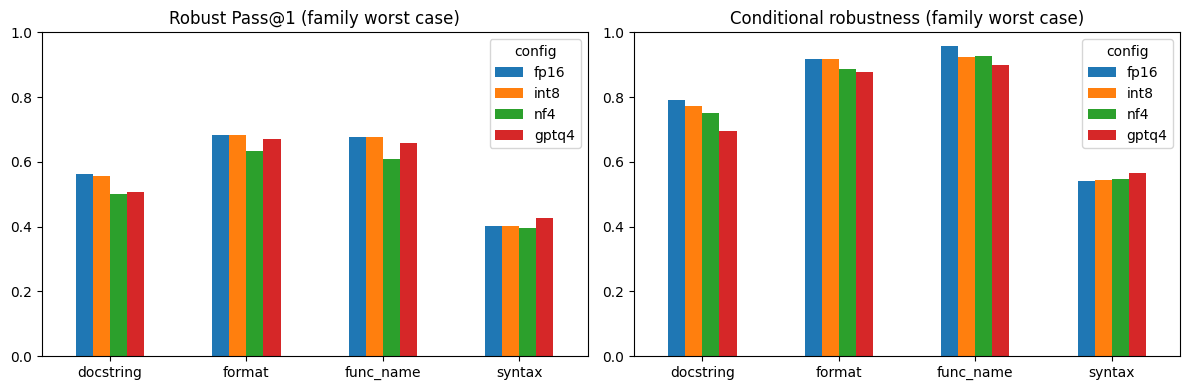

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
e1 = results[(results["eval"] == "E1") & results["variant"].str.endswith("worst_case")]
for ax, metric, title in [(axes[0], "robust_pass", "Robust Pass@1 (family worst case)"),
                          (axes[1], "conditional_robust", "Conditional robustness (family worst case)")]:
    t = e1[e1["metric"] == metric].pivot(index="variant", columns="config", values="value")[CONFIGS]
    t.index = [v.split("/")[0] for v in t.index]
    t.plot.bar(ax=ax, rot=0)
    ax.set_title(title); ax.set_ylim(0, 1); ax.set_xlabel("")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "e1_by_family.png"), dpi=150)
plt.show()

## 9. Part 6 — Report (15 pts)

Write the report in the markdown cells below. Short and specific beats long. Back every
claim with a number from `results` or `paired`.

**The confound you must handle.** A configuration that solves fewer nominal problems has
fewer problems left to break, so its *absolute* robust pass can drop less — and it can look
"more robust" for the wrong reason. Example: `fp16` solves 100 nominal problems and keeps
80 under a perturbation (20 lost); `nf4` solves 70 and keeps 60 (10 lost). Only 10 lost
looks better, yet conditional robustness is 80% for `fp16` and 86% for `nf4` — and whether
*that* gap is real is a question for Part 5. Report absolute and conditional numbers side by
side, and discuss any case where they disagree.

### 9.1 Quantization

*Library versions; for `gptq4`: calibration dataset, number of samples, sequence length, and
why you chose them. Efficiency table (size, memory, tokens/s) and what it does and does not
show (see the note on GPTQ decompression).*

TODO

We evaluated four configurations of **Qwen2.5-Coder-1.5B-Instruct**: FP16, INT8, NF4, and GPTQ4, using an NVIDIA L4 GPU.

**Environment:** PyTorch 2.11.0+cu130, Transformers 5.17.0, bitsandbytes 0.50.2, llmcompressor 0.14.0, and compressed-tensors 0.19.0.

**Quantization methods:**

- **FP16:** Original model with 16-bit weights.
- **INT8:** 8-bit quantization through bitsandbytes.
- **NF4:** 4-bit NF4 quantization through bitsandbytes, with FP16 computation.
- **GPTQ4:** GPTQ post-training quantization using W4A16, group size 128, with `lm_head` excluded.

For GPTQ calibration, we used `theblackcat102/evol-codealpaca-v1`, taking the first **256 examples**, truncated to a maximum of **512 tokens** each. We selected coding examples because they better represent the model's intended task than general text. The calibration dataset is separate from HumanEval and ReCode, avoiding evaluation-data leakage. GPTQ calibration used FP32 weights to avoid numerical instability.

**Efficiency results:**

| Configuration | Weights in memory (GB) | Peak GPU memory (GB) | Tokens/s |
|---|---:|---:|---:|
| FP16 | 3.09 | 6.38 | 118.55 |
| INT8 | 1.78 | 5.41 | 31.90 |
| NF4 | 1.12 | 4.50 | 92.96 |
| GPTQ4 | 3.11 | 6.40 | 93.41 |

The compressed GPTQ4 checkpoint occupies **1.64 GB on disk**.

**Observations:** NF4 achieved the lowest GPU memory usage. However, FP16 had the highest generation speed, while INT8 was substantially slower. Quantization therefore did not automatically improve inference speed.

GPTQ4 requires special interpretation. Although its checkpoint stores compressed 4-bit weights, Transformers decompressed them to FP16 during inference. Consequently, its measured GPU memory and speed do not represent what a dedicated 4-bit inference kernel could achieve.

These measurements demonstrate the memory and speed trade-offs of our implementations, rather than the maximum efficiency possible with each quantization method.

### 9.2 Results

*E0 and E1 per configuration, both absolute and conditional. Which perturbation families,
if any, does quantization make worse? Do `nf4` and `gptq4` differ? Which differences
survive the paired test, and which are within noise? Then E2 (ASL and the per-loop curve)
and/or E3 (spread across templates).*

TODO

**E0: Clean baseline**

We evaluated all four configurations on 164 HumanEval problems using greedy decoding.

| Dataset | FP16 | INT8 | NF4 | GPTQ4 |
|---|---:|---:|---:|---:|
| Nominal pass@1 | 70.1% | 72.0% | 65.9% | 72.0% |
| Nominal partial pass@1 | 74.4% | 73.8% | 70.1% | 75.6% |

NF4 had the lowest accuracy on both nominal datasets. INT8 and GPTQ4 slightly outperformed FP16 on ordinary HumanEval, showing that quantization does not necessarily reduce clean accuracy.

**E1: ReCode robustness**

The table reports each perturbation family's worst-case robust pass@1 and conditional robustness. Each value is expressed as **absolute / conditional**.

| Family | FP16 | INT8 | NF4 | GPTQ4 |
|---|---:|---:|---:|---:|
| Docstring | 56.1% / 79.1% | 55.5% / 77.1% | 50.0% / 75.0% | 50.6% / 69.5% |
| Function name | 67.7% / 95.7% | 67.7% / 92.4% | 61.0% / 92.6% | 65.9% / 89.8% |
| Syntax | 40.2% / 54.1% | 40.2% / 54.5% | 39.6% / 54.8% | 42.7% / 56.5% |
| Format | 68.3% / 91.8% | 68.3% / 91.7% | 63.4% / 88.7% | 67.1% / 87.9% |

Docstring perturbations caused the clearest robustness degradation after quantization. GPTQ4 achieved 72.0% nominal accuracy, compared with FP16's 70.1%, but its worst-case conditional docstring robustness was only 69.5%, versus 79.1% for FP16. Thus, better clean accuracy did not guarantee better robustness.

Syntax perturbations were difficult for every configuration. Under DeadCodeInserter, FP16's robust pass@1 was 44.5%, compared with 45.7% for NF4 and GPTQ4. There is no clear evidence that quantization specifically worsened this perturbation.

NF4 and GPTQ4 also behaved differently despite both using 4-bit weights. GPTQ4 had higher clean accuracy and better worst-case syntax robustness, but worse conditional robustness for docstring and format perturbations.

These differences are descriptive and should not automatically be treated as statistically significant.

**Paired statistical comparisons**

We compared each quantized configuration against FP16 on the same 164 problems using exact McNemar tests and paired bootstrap confidence intervals.

- NF4's clean pass@1 was 4.3 percentage points below FP16, but McNemar's test gave p = 0.065.
- NF4 had nominal p-values below 0.05 for CamelCase (p = 0.039) and ButterFinger function-name perturbations (p = 0.019).
- INT8 and GPTQ4 showed no individual comparison with p below 0.05.

There were 30 paired comparisons. Neither NF4 result survives a Bonferroni correction (threshold approximately 0.0017). Therefore, we cannot confidently claim that quantization caused a statistically significant degradation across these tests. The bootstrap intervals also show uncertainty, with some borderline differences.

**E2: EVALOOOP**

We evaluated self-consistency across three regeneration loops.

| Configuration | Loop 1 | Loop 2 | Loop 3 | ASL |
|---|---:|---:|---:|---:|
| FP16 | 70.1% | 43.9% | 40.9% | 1.549 |
| INT8 | 72.0% | 47.0% | 42.1% | 1.610 |
| NF4 | 65.9% | 43.9% | 42.1% | 1.518 |
| GPTQ4 | 72.0% | 44.5% | 41.5% | 1.579 |

The largest decline occurred between loops 1 and 2 for every configuration. Accuracy changed much less between loops 2 and 3.

INT8 achieved the highest ASL, followed by GPTQ4, FP16, and NF4. However, the differences were small, and ASL depends partly on initial clean accuracy.

Unlike the original EVALOOOP evaluation, our adaptation used HumanEval instead of MBPP+ and only three loops instead of ten. Greedy decoding can also lead to repeated outputs and fixed points. Therefore, these ASL values measure short-term regeneration stability under our protocol, not the full robustness captured by the original benchmark.

Overall, the results suggest that quantization can change robustness in ways that clean accuracy alone does not reveal. However, the evidence does not establish a consistent or statistically significant robustness penalty across all quantization methods.

### 9.3 Three flipped examples

*At least three problems that the `fp16` model solves under a perturbation and a quantized
model does not (or the reverse). For each: the perturbation, both completions (find them in
`SAMPLES`), and your explanation of what went wrong.*

TODO

In [33]:
# helper: find flips for one perturbation and show both completions
def flips(dataset, a="fp16", b="nf4", limit=5):
    pa, pb = PASS[a][dataset], PASS[b][dataset]
    ids = [t for t in pa if pa[t] and not pb[t]][:limit]
    for t in ids:
        for config in (a, b):
            s = next(s for s in SAMPLES if s["config"] == config and s["variant"] == dataset and s["item_id"] == t)
            print(f"===== {t} [{config}] {s['status']}")
            print(s["prompt"] + s["output"])
    return ids

flips("func_name/CamelCase")

===== HumanEval/19 [fp16] passed
from typing import List


def sortNumbers(numbers: str) -> str:
    """ Input is a space-delimited string of numberals from 'zero' to 'nine'.
    Valid choices are 'zero', 'one', 'two', 'three', 'four', 'five', 'six', 'seven', 'eight' and 'nine'.
    Return the string with numbers sorted from smallest to largest
    >>> sortNumbers('three one five')
    'one three five'
    """
    # Define a dictionary to map number words to their numeric values
    number_map = {
        'zero': 0, 'one': 1, 'two': 2, 'three': 3, 'four': 4,
        'five': 5, 'six': 6, 'seven': 7, 'eight': 8, 'nine': 9
    }
    
    # Split the input string into a list of number words
    number_words = numbers.split()
    
    # Sort the list of number words based on their numeric values
    sorted_number_words = sorted(number_words, key=lambda word: number_map[word])
    
    # Join the sorted list of number words back into a string
    sorted_numbers = ' '.join(sorted_number_words

['HumanEval/19',
 'HumanEval/20',
 'HumanEval/57',
 'HumanEval/65',
 'HumanEval/98']

We examined three problems where FP16 passed but NF4 failed under the **CamelCase function-name perturbation**. Both models received the same perturbed prompt. The snippets below reproduce the generated completion bodies, excluding the shared function signatures and docstrings.

### Example 1: HumanEval/57 - Monotonic sequence

**FP16 (passed):**

```python
increasing = decreasing = True
for i in range(1, len(l)):
    if l[i] > l[i - 1]:
        decreasing = False
    elif l[i] < l[i - 1]:
        increasing = False
return increasing or decreasing
```

**NF4 (failed, AssertionError):**

```python
increasing = all(x < y for x, y in zip(l, l[1:]))
decreasing = all(x > y for x, y in zip(l, l[1:]))
return increasing or decreasing
```

**Explanation:** NF4 used strict comparisons (`<` and `>`), which reject sequences containing equal adjacent elements. A monotonically increasing or decreasing sequence can include equal elements. FP16 correctly handles equality, while NF4 fails on these edge cases.

### Example 2: HumanEval/65 - Circular digit shift

**FP16 (passed):**

```python
num_str = str(x)
if shift > len(num_str):
    return num_str[::-1]
else:
    return num_str[-shift:] + num_str[:-shift]
```

**NF4 (failed, AssertionError):**

```python
if shift > len(str(x)):
    return str(x)[::-1]
else:
    return str(x)[shift:] + str(x)[:shift]
```

**Explanation:** The task requires a right circular shift. FP16 implements this using negative slice indices, while NF4 performs a left circular shift. The implementations can produce different results for the same input, causing NF4 to fail the tests.

### Example 3: HumanEval/98 - Uppercase vowels at even indices

**FP16 (passed):**

```python
count = 0
for i in range(0, len(s), 2):
    if s[i] in 'AEIOU':
        count += 1
return count
```

**NF4 (failed, AssertionError):**

```python
count = 0
for i in range(1, len(s), 2):
    if s[i] in 'AEIOU':
        count += 1
return count
```

**Explanation:** This is an indexing error. The task asks for uppercase vowels at even indices, starting from index 0. FP16 iterates over indices 0, 2, 4, and so on. NF4 starts at index 1, counting odd indices instead.

### Discussion

All three examples demonstrate how small changes in generated code can cause test failures. The NF4 errors involve comparison operators, slice direction, and index selection. These are subtle mistakes that can easily be missed without executing the generated code.

The results show individual failures under quantization, but they do not establish that CamelCase renaming specifically caused these errors. Identifying that interaction would require comparing the same problems under both nominal and perturbed prompts for each model.

### 9.4 Conclusion and threats to validity

*Your answer to the assignment's question, at the confidence your data supports. What could
make it wrong: one model, one seed per transformation, greedy decoding, the subset of
perturbations, the calibration set, decompressed GPTQ inference, and anything else you noticed.*

TODO

### Conclusion

Our results suggest that **quantization can affect code generation robustness, even when clean accuracy remains similar or improves**. However, the effect depends on the quantization method and the type of perturbation.

GPTQ4 achieved a clean pass@1 of 72.0%, slightly higher than FP16's 70.1%. Despite this, its worst-case conditional robustness under docstring perturbations dropped from 79.1% to 69.5%. This suggests that clean accuracy alone does not capture how reliably a model handles changes in prompts.

NF4 showed lower clean accuracy (65.9%) and generally weaker robustness than FP16. INT8, on the other hand, performed comparably to FP16 across most evaluations. The EVALOOOP results also showed relatively small differences in average sustainable loops across configurations.

**We therefore cannot conclude that quantization consistently makes coding models more brittle.** Although some individual comparisons showed statistically significant differences before correction, none survived correction for multiple comparisons. Our evidence supports a more limited conclusion: quantization can change model behavior and robustness, but the direction and magnitude vary.

### Threats to validity

- **Single model:** We evaluated only Qwen2.5-Coder-1.5B-Instruct. Larger models or different architectures might behave differently.
- **Limited benchmark coverage:** We used 164 HumanEval problems and a fixed subset of ReCode perturbations. These may not represent real-world software development.
- **Limited randomness:** We used greedy decoding and one perturbation seed. Different decoding strategies or perturbation seeds could produce different results.
- **GPTQ inference:** GPTQ4 weights were decompressed during inference, so its measured memory and speed do not represent optimized 4-bit inference.
- **EVALOOOP adaptation:** We used three loops instead of ten and HumanEval instead of MBPP+. This limits comparisons with the original paper.
- **Statistical uncertainty:** Many comparisons were performed on the same 164 problems. Small differences may reflect sampling variation, and multiple comparisons increase the chance of false positives.

Overall, evaluating quantized coding models requires both clean accuracy and robustness measurements. A model that performs well on standard prompts may still behave differently when those prompts are modified.

### 9.5 AI assistance

*What you used and for what.*

TODO

I used **ChatGPT (OpenAI, GPT-6)** to assist with this assignment.

AI assistance included:

- Implementing the Python functions marked as TODO, including model loading, GPTQ quantization, robustness metrics, EVALOOOP, and paired statistical tests.
- Explaining GPTQ, its calibration process, and how quantization errors are corrected.
- Reviewing notebook execution outputs and helping troubleshoot the evaluation workflow.
- Interpreting experimental results, statistical comparisons, and examples where model predictions differed.
- Drafting the report sections using the experimental results.

The experiments were executed in Google Colab using an NVIDIA T4 GPU initially and an L4 GPU for the full evaluation. I reviewed the implementations and results.

## 10. Part 7 — Submit

Run the check below. It only checks that the run is complete, not that it is correct.

Then upload **two files** to Gradescope:

1. **This notebook, with all its outputs.** Run it top to bottom with `QUICK = False`, then
   *File → Download → Download .ipynb*. A notebook without outputs cannot be graded.
2. **`README.md`** explaining your code. Keep it short — a few lines per item:
   - how to run the notebook, and the library versions you used (Part 0 prints them);
   - for each TODO: what your implementation does and any choice you made — in particular
     the GPTQ calibration dataset, number of samples and sequence length, and why;
   - every place you departed from a paper's protocol (ReCode, EVALOOOP, Sclar et al.), and why;
   - which of E2 / E3 you ran;
   - any material AI assistance.

The report itself (results, flipped examples, conclusion) stays in Part 6 of the notebook.

In [32]:
def check_complete():
    df = pd.DataFrame(RESULTS)
    problems = []
    if QUICK:
        problems.append("QUICK is still True: the graded run must use all 164 problems")
    for config in CONFIG_META:
        if not ((df["config"] == config) & (df["eval"] == "E0")).any():
            problems.append(f"no E0 result for {config}")
        for family in RECODE_SUBSET:
            if not ((df["config"] == config) & (df["variant"] == f"{family}/worst_case")).any():
                problems.append(f"no E1 {family} result for {config}")
    if not (df["eval"].isin(["E2", "E3"])).any():
        problems.append("neither E2 nor E3 was run")
    if df["value"].isna().any():
        problems.append("some result values are missing")
    print("\n".join(problems) or "run complete - download the notebook and write your README")
    return not problems


check_complete()

run complete - download the notebook and write your README


True